# 1. Install Dependencies and Setup

In [1]:
!pip list | findstr /C:"tensorflow"




tensorflow                   2.16.1
tensorflow-intel             2.16.1
tensorflow-io-gcs-filesystem 0.31.0



[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install tensorflow



[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# !pip install tensorflow tensorflow-gpu opencv-python matplotlib


In [4]:
!pip install tensorflow opencv-python matplotlib




[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!pip list

Package                      Version
---------------------------- --------
absl-py                      2.1.0
anyio                        3.7.0
argon2-cffi                  21.3.0
argon2-cffi-bindings         21.2.0
arrow                        1.2.3
asttokens                    2.2.1
astunparse                   1.6.3
async-lru                    2.0.2
attrs                        23.1.0
Babel                        2.12.1
backcall                     0.2.0
beautifulsoup4               4.12.2
bleach                       6.0.0
cachetools                   5.3.3
certifi                      2023.5.7
cffi                         1.15.1
chardet                      5.2.0
charset-normalizer           3.1.0
colorama                     0.4.6
comm                         0.1.3
contourpy                    1.1.0
cryptography                 42.0.6
cycler                       0.11.0
debugpy                      1.6.7
decorator                    5.1.1
defusedxml                   0.7.1
exec


[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import tensorflow as tf
import os

In [7]:
# Avoid OOM errors by setting GPU Memory Consumption Growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus: 
    tf.config.experimental.set_memory_growth(gpu, True)

In [8]:
tf.config.list_physical_devices('GPU')

[]

# 2. Remove dodgy images

In [9]:
!pip install pillow


[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import cv2
# import imghdr
from PIL import Image
import os

In [11]:
data_dir = 'comp432' 

In [12]:
image_exts = ['jpeg','jpg', 'bmp', 'png']

In [13]:
for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try:
            # Open the image using PIL
            with Image.open(image_path) as img:
                # Get the format of the image
                img_format = img.format.lower()
                
                # Check if the format is in the allowed extensions list
                if img_format not in image_exts:
                    print('Image not in ext list {}'.format(image_path))
                    os.remove(image_path)
        except Exception as e:
            print('Issue with image {}'.format(image_path))
             # os.remove(image_path)

# 3. Load Data

In [14]:
import numpy as np
from matplotlib import pyplot as plt

In [15]:
# to build data pipeline, so rather thanloading everything into memory, which allows you to scale to much larger
# it also gives you a repeatable set of steps
# A data pipeline is a series of steps or processes that are used to ingest, process, transform, and analyze data. 
# It's essentially a workflow that facilitates the movement of data from its source to its destination in a structured and efficient manner
data = tf.keras.utils.image_dataset_from_directory('comp432') 

Found 250 files belonging to 2 classes.


In [16]:
# allows us to access the data from our data pipeline
# it automatichally reshapes our images to make sure they have a consistent size.
data_iterator = data.as_numpy_iterator()

In [17]:
# get us a batch back (the data)
# actually acessing the data pipeline
batch = data_iterator.next()


In [18]:
batch[1]
# labels 
# 1 = imposter
# 0 = genuine

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 1, 1, 1])

NOTE: there are two parts of a dataset, the images themself and their labels.

so batch holds our data (images) as numpy arrays 



In [19]:
batch[0]
# our imahges as numpy array

array([[[[255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         ...,
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ]],

        [[255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         ...,
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ]],

        [[255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         ...,
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ]],

        ...,

        [[255.      , 255.      , 255.      ],
         [255.      , 255.      , 255.      ]

In [20]:
batch[0].shape

(32, 256, 256, 3)

we got 32 images of shape 256X256 by three channels
these color channels "rgb" each has a value ranging from 0-255 

now when building AI models we want our values to be as small as possible so our model can generate faster 

and the optimal way to do is by scaling the data 

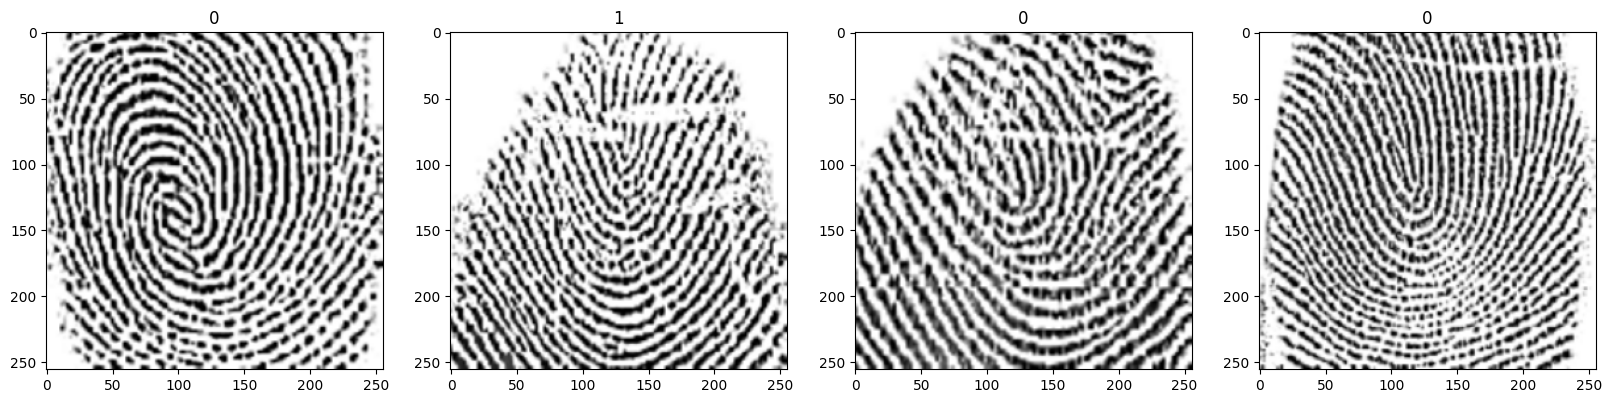

In [21]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
     ax[idx].imshow(img.astype(int))
     ax[idx].title.set_text(batch[1][idx])


these images have label of 1 and 0 where 1 represent imposter and zero represent genuine

# 4. Scale Data

In [22]:

# x is going to represent our images [independant var], and y is our target var
# no transformation on 'y'
data = data.map(lambda x,y: (x/255, y))


 map function is being performed as our data is being preprossed thru the data pipeline.
 
 Perform transformation in pipeline.

 scaling data by dividing value by 255
 so instead of our images values ranging from 0-255, they range from 0 to 1.

In [23]:
# access to our iterator and next is going ro grab our next batch
data.as_numpy_iterator().next()

(array([[[[1.        , 1.        , 1.        ],
          [1.        , 1.        , 1.        ],
          [1.        , 1.        , 1.        ],
          ...,
          [0.87922794, 0.87922794, 0.87922794],
          [0.91746324, 0.91746324, 0.91746324],
          [0.9411765 , 0.9411765 , 0.9411765 ]],
 
         [[1.        , 1.        , 1.        ],
          [1.        , 1.        , 1.        ],
          [1.        , 1.        , 1.        ],
          ...,
          [0.8466222 , 0.8466222 , 0.8466222 ],
          [0.86839   , 0.86839   , 0.86839   ],
          [0.8779412 , 0.8779412 , 0.8779412 ]],
 
         [[1.        , 1.        , 1.        ],
          [1.        , 1.        , 1.        ],
          [1.        , 1.        , 1.        ],
          ...,
          [0.83827835, 0.83827835, 0.83827835],
          [0.84447956, 0.84447956, 0.84447956],
          [0.839951  , 0.839951  , 0.839951  ]],
 
         ...,
 
         [[0.18578431, 0.18578431, 0.18578431],
          [0.34650

In [24]:
# access to our iterator and next is going ro grab our next batch
scaled_iterator = data.as_numpy_iterator().next()[0].max()
scaled_iterator

1.0

# 5. Split Data

In [25]:
len(data)

8

In [26]:
train_size = int(len(data)*.7)
val_size = int(len(data)*.2)+1
test_size = int(len(data)*.1)

In [27]:
print(train_size)
print(val_size)
print(test_size)
print(train_size + val_size + test_size)


5
2
0
7


In [28]:
train = data.take(train_size)
# skip the batches that were already allocated to our training partitions
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)
print("train: ", len(train) , "\n val:" , len(val), "\n test:" , len(test))

train:  5 
 val: 2 
 test: 0


the 'take' method defines hhow much data we are going to take in that oarticular partition

# 6. Build Deep Learning Model

In [29]:
train

<_TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [30]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, Input

In [31]:
model = Sequential()

Sequential API for simpler, linear models with a single input and a single output, where layers are stacked sequentially

Functional API for more complex models with multiple inputs/outputs or with intricate architectures like residual connections or shared layers.

In [32]:
# model.add(Conv2D(16, (3,3), 1, activation='relu', input_shape=(256,256,3)))
# model.add(MaxPooling2D())
# model.add(Conv2D(32, (3,3), 1, activation='relu'))
# model.add(MaxPooling2D())
# model.add(Conv2D(16, (3,3), 1, activation='relu'))
# model.add(MaxPooling2D())
# model.add(Flatten())
# model.add(Dense(256, activation='relu'))
# model.add(Dense(1, activation='sigmoid'))

# why?

 relu is going to take the output of that conv layer and pass it to a function that is going to convert outputs 
beloqw zero to zero and its going to preserve positive values

this helps us taking into account non-linear patterns


-why relu?????

In [33]:
model.add(Input(shape=(256, 256, 3)))  # Input layer , First layer
# 16 filters, each filter has 3X3 pixles and filters are gonna move one pixle at a time

model.add(Conv2D(16, (3,3), 1, activation='relu'))
# MaxPooling layer  takes the maximum value after the relu activation and its going to turn back that value
# its effectivly going to condense that inforrmation - reduce image data
model.add(MaxPooling2D())
model.add(Conv2D(32, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())
model.add(Conv2D(16, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())
#  filters are going to be the last channel
 
# after applying conv layers all those filters are going to condense the rows
# and the width and then the number of filters will form the channel values 
# get a single value
model.add(Flatten())

# fully connected layers
# 256 nuerons
model.add(Dense(256, activation='relu'))
# final layer is a single dense layer = single output which is zero or one
model.add(Dense(1, activation='sigmoid'))
# sigmoid function return a value of zero or one  which in our case is going to map to a genuine or imposter user

three conv layers, two dense layer

dense layer serves to transform the spatially-organized features extracted by the convolutional layers into a flat vector format suitable for classification or regression tasks. It applies a matrix multiplication operation followed by a non-linear activation function to produce the final output of the network.

we are taking all of the outputs from a layer and we are passing it to an activation function to modify what the output looks like

In [34]:
# adam is an optimizer
# so  far its binary classification so we used 'BinaryCrossentropy'
model.compile('adam', loss=tf.losses.BinaryCrossentropy(), metrics=['accuracy'])

 optimizers are responsible for adjusting the parameters (weights and biases) of the network during training to minimize the loss function. The goal of optimization is to find the optimal set of parameters that minimize the difference between the predicted output of the model and the actual target output.

In [35]:
# the output of our third conv layer is shaped as : (None, 30, 30, 16)  
30*30*16
# result is the number of inputs to the flattening layer that are pasesd to it from the third conv layer 
# which shows us how the flattening layer converts our inputs from multi dimention to one

14400

In [36]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 254, 254, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 127, 127, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 125, 125, 32)        │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 60, 60, 16)          │           4,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 30, 30, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 14400)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │       3,686,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,696,625 (14.10 MB)

 Trainable params: 3,696,625 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

param # from the last dense layer is the number of nuerons plus our output node so 256 + 1 =257

# 7. Train

In [37]:
# just a var that points to logs
logdir='logs'

In [38]:
# save model at a specific checkpoint 
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [39]:
# take training data which was 8 batches
# epochs is how long are we training for, one epoch is one run over our entire training set of data
# then run evaluation on our validation data so we can see how well our model perform in real time

hist = model.fit(train, epochs=22, validation_data=val, callbacks=[tensorboard_callback])

Epoch 1/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 250ms/step - accuracy: 0.5477 - loss: 2.0472 - val_accuracy: 0.4688 - val_loss: 1.0520
Epoch 2/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 182ms/step - accuracy: 0.4785 - loss: 0.8158 - val_accuracy: 0.4844 - val_loss: 0.7069
Epoch 3/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.5425 - loss: 0.6886 - val_accuracy: 0.4375 - val_loss: 0.7337
Epoch 4/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 174ms/step - accuracy: 0.5767 - loss: 0.6789 - val_accuracy: 0.5312 - val_loss: 0.6712
Epoch 5/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step - accuracy: 0.5644 - loss: 0.6641 - val_accuracy: 0.6875 - val_loss: 0.6411
Epoch 6/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 158ms/step - accuracy: 0.7030 - loss: 0.6271 - val_accuracy: 0.3906 - val_loss: 0.8026
Epoch 7/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.5138 - loss: 0.7178 - val_accuracy: 0.8125 - val_loss: 0.6176
Epoch 8/22
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 161ms/step - accuracy: 0.7265 - loss: 0.6250 - val_accuracy: 0.9531 - val_loss:

# 8. Plot Performance

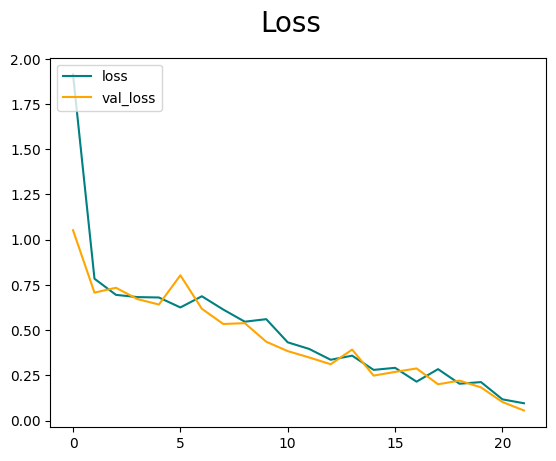

In [40]:
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

Note: if 'Loss' started going up that means that we are overfitting.
Solution to that is regularization. 

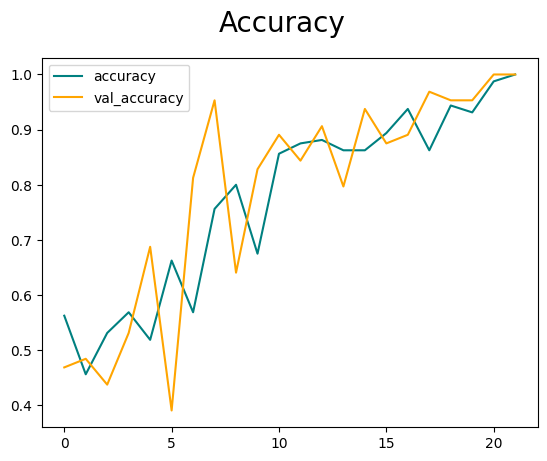

In [41]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color='teal', label='accuracy')
plt.plot(hist.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc="upper left")
plt.show()

# 9. Evaluate

In [42]:
from tensorflow.keras.metrics import Precision, Recall, BinaryAccuracy

In [43]:
pre = Precision()
re = Recall()
acc = BinaryAccuracy()

precision, recall and accuracy are three diffrent  metrics that are used here to test how well our model is performing.

In [44]:
for batch in test.as_numpy_iterator(): 
    # x is set of images and y is our true value 
    X, y = batch
    # yhat is going to return a set of values between 0 and 1 and thats because we used sigmoid (binary classification)
    yhat = model.predict(X)
    pre.update_state(y, yhat)
    re.update_state(y, yhat)
    acc.update_state(y, yhat)
print(f' precision: {pre.result().numpy()}, recall: {re.result().numpy()} , accuracy: {acc.result().numpy()}')

 precision: 0.0, recall: 0.0 , accuracy: 0.0


In [45]:
print(pre.result(), re.result(), acc.result())

tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(0.0, shape=(), dtype=float32)


# 10. Test

In [46]:
import cv2

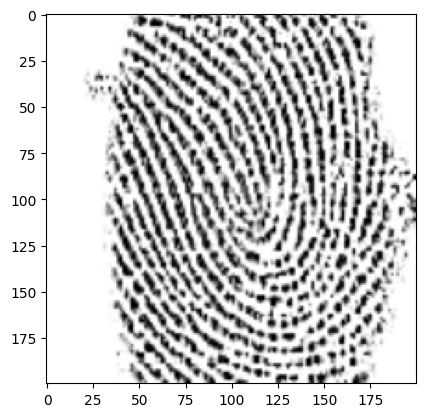

In [52]:
img = cv2.imread('314.jpg')
plt.imshow(img)
plt.show()

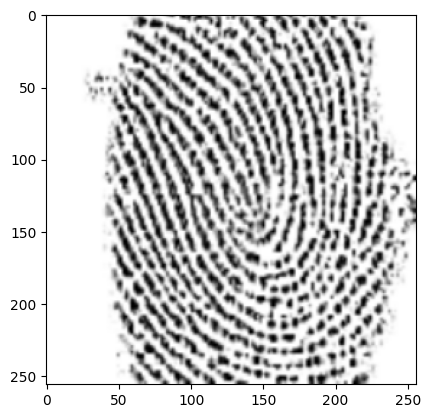

In [53]:
resize = tf.image.resize(img, (256,256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [54]:
yhat = model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


In [55]:
yhat

array([[0.90877926]], dtype=float32)

In [56]:
if yhat > 0.65: 
    print(f'Predicted class is imposter')
else:
    print(f'Predicted class is genuine')

Predicted class is imposter
